# Diabetes (Pima) – Diagnóstico de diabetes


**Contexto:** predecir si una paciente (mujer Pima, de 21 años o más) tiene diabetes (`Outcome = yes`).

- Todas las variables predictoras son numéricas.
- **Hay muchos valores faltantes** (`Insulin` ≈ 49 %, `SkinThickness` ≈ 30 %, `Pregnancies` ≈ 14 %...), así que se
  **comparan métodos de imputación** (media, mediana, KNN, MICE) con validación cruzada.
- Hay desbalance moderado (65 % / 35 %), así que también se comparan técnicas de balanceo.

**Modelo asignado: KNN**, por estas razones:
1. **Todas las variables son numéricas y continuas**, así que la distancia euclidiana o manhattan entre pacientes
   (ya estandarizadas) tiene sentido directo: "pacientes con glucosa, IMC y edad parecidos tienen el mismo diagnóstico".
2. Hace pocos supuestos sobre la forma de la frontera de decisión (es un modelo no paramétrico).
3. Encaja con el preprocesamiento que exige esta data: imputación, escalado y balanceo, todo dentro del pipeline.


**Flujo:** Datos → EDA → Train/Test → Outliers → Imputación → Balanceo → **KNN** → Evaluación final → Conclusiones

> Todos los preprocesamientos van **dentro de un Pipeline**, así se ajustan solo con los datos de
> entrenamiento de cada fold y se evita *data leakage*.

## 0. Librerías y configuración

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LogisticRegression, BayesianRidge
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import IsolationForest
from sklearn.covariance import EllipticEnvelope
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC, BorderlineSMOTE, ADASYN
from imblearn.combine import SMOTETomek, SMOTEENN

# Semilla para reproducibilidad
SEMILLA = 42
# Metrica objetivo a evaluar
SCORING = "f1"
# Validacion cruzada
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = SEMILLA)

## 1. Cargar datos



In [22]:
try:
    from google.colab import files
    subido = files.upload()
    ARCHIVO = list(subido.keys())[0]
except ImportError:
    ARCHIVO = "Diabetes.xlsx"

df = pd.read_excel(ARCHIVO)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.0,35.0,NaN,33.6,0.627,50,yes
1,1.0,85.0,66.0,29.0,NaN,26.6,0.351,31,no
2,8.0,183.0,64.0,NaN,NaN,23.3,0.672,32,yes
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21,no
4,NaN,137.0,40.0,35.0,168.0,43.1,2.288,33,yes


## 2. Análisis exploratorio (EDA)

In [23]:
TARGET   = "Outcome"
num_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
cat_cols = []
NOMBRES_CLASE = ["No diabetes (0)", "Diabetes (1)"]

y = (df[TARGET].str.strip().str.lower() == "yes").astype(int)   # 1 = yes (diabetes)
X = df[num_cols + cat_cols].copy()

print("Tipos de variables:\n", df.dtypes, "\n")
print("Valores faltantes por variable:\n", df.isnull().sum(), "\n")
print("Distribución de la variable respuesta:")
print(pd.DataFrame({"n": y.value_counts(), "%": (y.value_counts(normalize = True) * 100).round(1)}))
df[num_cols].describe().T.round(2)

Tipos de variables:
 Pregnancies                 float64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                         str
dtype: object 

Valores faltantes por variable:
 Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64 

Distribución de la variable respuesta:
           n     %
Outcome           
0        500  65.1
1        268  34.9


,count,mean,std,min,25%,50%,75%,max
Pregnancies,657.0,4.49,3.22,1.00,2.00,4.00,7.00,17.00
Glucose,763.0,121.69,30.54,44.00,99.00,117.00,141.00,199.00
BloodPressure,733.0,72.41,12.38,24.00,64.00,72.00,80.00,122.00
SkinThickness,541.0,29.15,10.48,7.00,22.00,29.00,36.00,99.00
Insulin,394.0,155.55,118.78,14.00,76.25,125.00,190.00,846.00
BMI,757.0,32.46,6.92,18.20,27.50,32.30,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00


### 2.1. Análisis Univariado

El objetivo de inspeccionar las distribuciones univariadas condicionadas a la variable respuesta (`Outcome`) es evaluar el **poder discriminante individual** de cada predictor, identificar asimetrías y contextualizar los valores faltantes antes de definir el preprocesamiento:

* **Capacidad de separación para KNN:** En los histogramas se observa que variables como **`Glucose`**, **`BMI`** y **`Age`** presentan un desplazamiento claro entre las distribuciones de pacientes sanas (`0`) y diabéticas (`1`). Dado que **KNN** clasifica en función de la proximidad geométrica, estas variables actuarán como los ejes principales para clasificar cada clase.
* **Asimetría y escalas dispares:** Variables como `Insulin`, `DiabetesPedigreeFunction` y `Age` muestran una marcada asimetría positiva (cola hacia la derecha) y rangos numéricos muy distintos (por ejemplo, `Insulin` alcanza valores de $846\ \mu\text{U/ml}$, mientras que `DiabetesPedigreeFunction` se mueve entre $0.08$ y $2.42$). Esto hace **obligatorio el uso de estandarización (`StandardScaler`)** dentro del pipeline para evitar que las variables de mayor magnitud dominen el cálculo de distancias euclidianas o manhattan.
* **Naturaleza de los valores faltantes:** Se observa una alta proporción de datos ausentes en `Insulin` ($\approx 48.7\%$) y `SkinThickness` ($\approx 29.6\%$). Asimismo, `Pregnancies` registra $111$ valores faltantes ($\approx 14.5\%$).

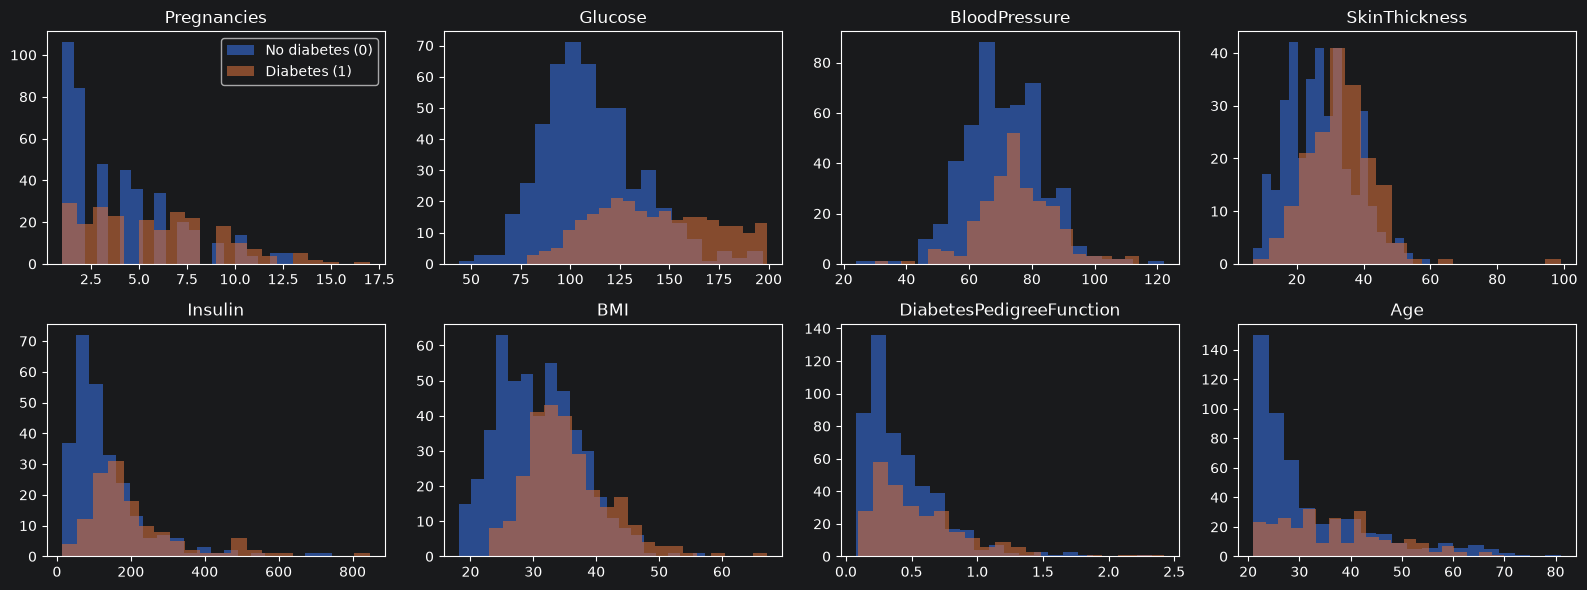

In [24]:
# Histogramas de las variables numéricas, separados por clase
n = len(num_cols); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize = (4 * ncol, 3 * nrow))
for ax, col in zip(np.ravel(axes), num_cols):
    for k, lab in zip([0, 1], NOMBRES_CLASE):
        ax.hist(X.loc[y == k, col].dropna(), bins = 20, alpha = 0.6, label = lab)
    ax.set_title(col)
for ax in np.ravel(axes)[n:]:
    ax.axis("off")
np.ravel(axes)[0].legend()
plt.tight_layout(); plt.show()

### 2.2. Análisis Bivariado (Correlación entre predictores y su impacto en KNN)

Más allá del comportamiento individual de cada variable, en un modelo basado en distancias como **KNN** es fundamental explorar cómo se relacionan las variables entre sí por dos motivos teóricos clave:

1. **Cómo afecta la correlación al cálculo de distancias en KNN:**
   KNN asume que todas las variables aportan información independiente y les asigna el mismo peso al calcular la distancia (euclidiana o manhattan) entre dos pacientes. Si dos variables están altamente correlacionadas (colinealidad), ambas miden en el fondo el mismo fenómeno biológico. Para KNN, esto equivale a **duplicar el peso de esa característica** al medir qué tan parecidos son dos puntos, deformando el espacio geométrico y restándole importancia al resto de variables. Por ello, este gráfico nos permite verificar si existe información redundante que pueda sesgar la vecindad de los datos.

2. **Cómo orienta la estrategia de imputación de datos faltantes:**
   Dado que tenemos variables con una gran cantidad de datos ausentes (como `Insulin` y `SkinThickness`), necesitamos saber si estas guardan relación con otras variables que sí están completas (como `Glucose` o `BMI`).
   * Si las variables fueran totalmente independientes entre sí (correlaciones cercanas a cero), rellenar los vacíos con la media o la mediana sería suficiente.
   * En cambio, si existen correlaciones claras entre ellas, usar una media o mediana simple destruiría esa relación natural y crearía pacientes con combinaciones de datos poco realistas (afectando directamente los vecinos que encontrará KNN). Verificar que existe correlación justifica poner a prueba métodos de imputación más avanzados (como **KNNImputer** o **MICE**), los cuales aprovechan justamente la información de las demás columnas para estimar el valor faltante de forma más coherente.

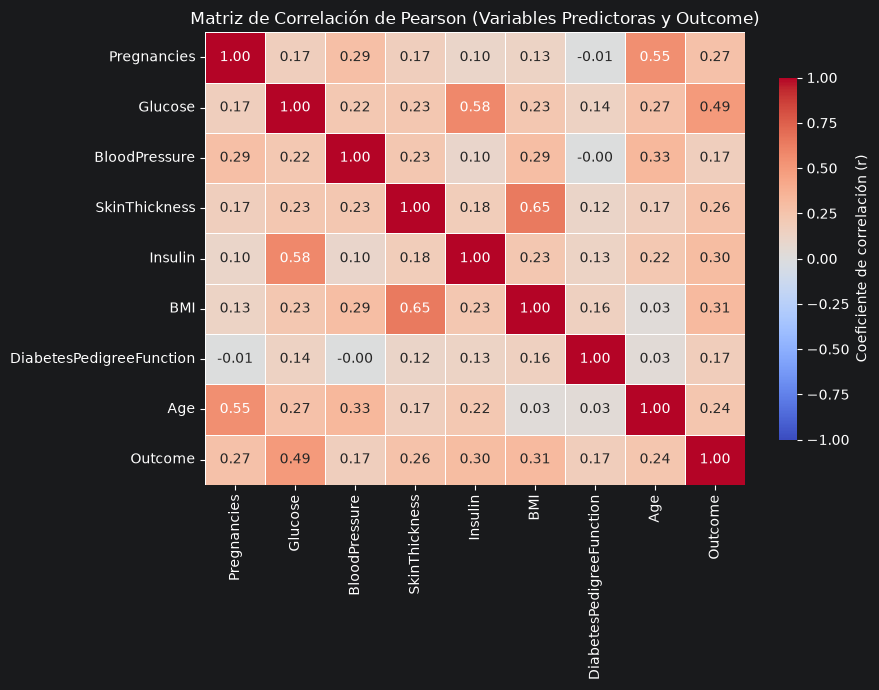

In [25]:
# Matriz de correlación de Pearson
corr_matrix = X.assign(Outcome = y).corr(method = "pearson")

plt.figure(figsize = (9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype = bool), k = 1)
sns.heatmap(
    corr_matrix,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm",
    vmin = -1, vmax = 1,
    linewidths = 0.5,
    cbar_kws = {"shrink": 0.8, "label": "Coeficiente de correlación (r)"}
)
plt.title("Matriz de Correlación de Pearson (Variables Predictoras y Outcome)")
plt.tight_layout()
plt.show()

**Observaciones del mapa de calor y alternativas frente a KNN:**

1. **¿Qué nos muestran los datos?**
   * Existen tres correlaciones moderadas-altas entre predictores: **`BMI` y `SkinThickness` ($0.65$)**, **`Glucose` e `Insulin` ($0.58$)**, y **`Age` y `Pregnancies` ($0.55$)**.
   * Respecto al diagnóstico (`Outcome`), **`Glucose` ($0.49$)** es la variable con mayor relación lineal, mientras que variables como `BloodPressure` ($0.17$) o `DiabetesPedigreeFunction` ($0.17$) tienen una relación lineal más débil por sí solas.

2. **Alternativas para que KNN no se vea perjudicado:**
   * **Aprovechar las correlaciones para imputar mejor:** Dado que `Insulin` y `SkinThickness` son justamente las columnas con más vacíos, sus correlaciones de $0.58$ y $0.65$ con variables casi completas (`Glucose` y `BMI`) son una ventaja. Nos permiten usar **MICE** o **KNNImputer** para rellenar esos huecos con valores coherentes antes de medir distancias.
   * **No eliminar variables a ciegas:** Aunque hay correlaciones de $0.55 - 0.65$, ninguna llega a niveles de colinealidad extrema ($> 0.80$) que obliguen a descartar columnas de inmediato. Sin embargo, como en KNN las variables ruidosas o redundantes pueden ensuciar el cálculo de la distancia euclidiana, tenemos tres alternativas prácticas dentro de nuestro flujo:
     1. **Probar la distancia Manhattan (`metric = "manhattan"` en el GridSearch):** A diferencia de la distancia Euclidiana (que eleva las diferencias al cuadrado y amplifica el efecto de variables redundantes o valores extremos), Manhattan suma diferencias absolutas y suele ser más estable cuando hay correlación moderada.
     2. **Ponderar vecinos por distancia (`weights = "distance"`):** Ayuda a que los vecinos realmente cercanos en todas las dimensiones pesen más que aquellos que quedaron dentro del radio $K$ por culpa de una variable ruidosa.
     3. **Evaluar selección de variables / descarte de columnas críticas:** Si tras el pipeline base notamos que las columnas con muchos faltantes e información redundante (`Insulin` o `SkinThickness`) meten ruido, una alternativa sencilla es probar el mismo pipeline excluyendo dichas columnas para ver si la métrica F1 mejora en validación cruzada.

## 3. Partición Train / Test (80 / 20, estratificada)
Se hace **antes** de cualquier preprocesamiento.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.20, random_state = SEMILLA, stratify = y
)
print(f"Train: {X_train.shape[0]} obs | Test: {X_test.shape[0]} obs")
print("Proporción clase 1 -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

# Niveles de cada categórica (se fijan con el dominio de la variable, no con la respuesta)
CATEGORIAS = {col: sorted(X[col].unique()) for col in cat_cols}

Train: 614 obs | Test: 154 obs
Proporción clase 1 -> train: 0.349 | test: 0.351


## 4. Detección de outliers (en TRAIN, con las variables numéricas)
Métodos **univariados** (Z-Score, IQR, MAD) y **multivariados** (Isolation Forest, LOF, Elliptic Envelope).
Igual que en clase, aquí solo se **identifican**; la decisión de eliminar o no.

             n_outliers  % train
Z-Score              35      5.7
IQR                  68     11.1
MAD                  45      7.3
IForest              31      5.0
LOF                  31      5.0
Elliptic             31      5.0
Todos Uni            31      5.0
Todos Multi          12      2.0
Todos                 9      1.5


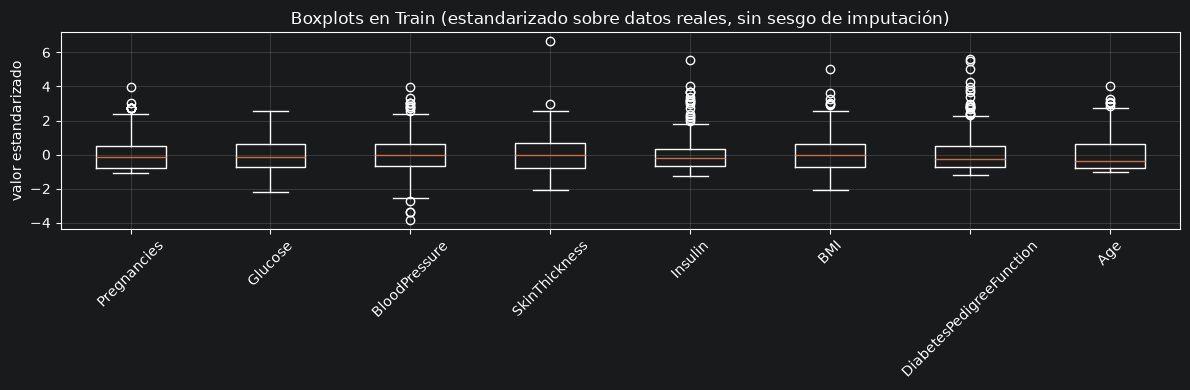

In [27]:
# --- MÉTODOS UNIVARIADOS ---
# Se evalúan sobre los datos originales (ignorando NaN por columna) para evitar que una
# imputación previa encoja artificialmente la varianza/IQR y dispare falsos outliers.

def get_outliers_zscore(X, threshold = 3):
    # nan_policy="omit" calcula media y desv. estándar solo con datos reales; nan_to_num evita warnings al comparar
    z = np.abs(stats.zscore(X, nan_policy = "omit"))
    return np.any(np.nan_to_num(z, nan = 0.0) > threshold, axis = 1)

def get_outliers_iqr(X, multiplier = 1.5):
    mask = np.zeros(X.shape[0], dtype = bool)
    for j in range(X.shape[1]):
        col = X[:, j]
        # np.nanpercentile ignora los vacíos para no aplastar la caja (Q1-Q3) en variables como Insulin
        q1, q3 = np.nanpercentile(col, [25, 75]); iqr = q3 - q1
        mask |= (col < q1 - multiplier * iqr) | (col > q3 + multiplier * iqr)
    return mask

def get_outliers_mad(X, threshold = 3.5):
    mask = np.zeros(X.shape[0], dtype = bool)
    for j in range(X.shape[1]):
        col = X[:, j]
        # np.nanmedian evita que el ~50% de faltantes en Insulin colapse el MAD a un valor cercano a 0
        med = np.nanmedian(col); mad = np.nanmedian(np.abs(col - med))
        if mad > 0:
            mask |= np.abs(0.6745 * (col - med) / mad) > threshold
    return mask

# --- MÉTODOS MULTIVARIADOS ---
# Requieren filas completas (sin NaN). Evalúan si la combinación clínica del paciente es anómala.

def get_outliers_iforest(X, contamination = 0.05):
    Xs = StandardScaler().fit_transform(X)
    return IsolationForest(contamination = contamination, random_state = SEMILLA).fit_predict(Xs) == -1

def get_outliers_lof(X, contamination = 0.05):
    Xs = StandardScaler().fit_transform(X)
    return LocalOutlierFactor(contamination = contamination).fit_predict(Xs) == -1

def get_outliers_elliptic(X, contamination = 0.05):
    Xs = StandardScaler().fit_transform(X)
    return EllipticEnvelope(contamination = contamination, random_state = SEMILLA).fit_predict(Xs) == -1

# Matriz original con NaN para métodos univariados
X_num_raw = X_train[num_cols].to_numpy(dtype = float)

# Los detectores multivariados no aceptan NaN: se pre-imputa con KNNImputer (y no con la mediana)
# para preservar la correlación entre variables y no inventar combinaciones clínicas falsas
X_num_tr = KNNImputer(n_neighbors = 5).fit_transform(X_num_raw)

mascaras = {
    "Z-Score":  get_outliers_zscore(X_num_raw),
    "IQR":      get_outliers_iqr(X_num_raw),
    "MAD":      get_outliers_mad(X_num_raw),
    "IForest":  get_outliers_iforest(X_num_tr),
    "LOF":      get_outliers_lof(X_num_tr),
    "Elliptic": get_outliers_elliptic(X_num_tr),
}
mascaras["Todos Uni"]   = mascaras["Z-Score"] & mascaras["IQR"] & mascaras["MAD"]
mascaras["Todos Multi"] = mascaras["IForest"] & mascaras["LOF"] & mascaras["Elliptic"]
mascaras["Todos"]       = mascaras["Todos Uni"] & mascaras["Todos Multi"]

tabla_out = pd.DataFrame({"n_outliers": {k: int(v.sum()) for k, v in mascaras.items()}})
tabla_out["% train"] = (tabla_out["n_outliers"] / len(X_train) * 100).round(1)
print(tabla_out)

# Boxplot estandarizando cada columna sobre sus valores reales (ignorando NaN)
plt.figure(figsize = (12, 4))
Xs_plot = StandardScaler().fit_transform(X_num_raw)
datos_boxplot = [Xs_plot[~np.isnan(Xs_plot[:, j]), j] for j in range(len(num_cols))]
plt.boxplot(datos_boxplot)
plt.xticks(range(1, len(num_cols) + 1), num_cols, rotation = 45); plt.ylabel("valor estandarizado")
plt.title("Boxplots en Train (estandarizado sobre datos reales, sin sesgo de imputación)")
plt.grid(alpha = 0.3); plt.tight_layout(); plt.show()

In [28]:
# --- ANALISIS DE OUTLIERS: Prevalencia de diabetes ---
# Evaluamos cuántas observaciones marca cada criterio y qué porcentaje de ellas pertenece
# realmente a pacientes con diabetes (Clase 1), comparándolo con la prevalencia base (34.9%).

auditoria_out = {}
prevalencia_base = y_train.mean() * 100

for nombre, mask in mascaras.items():
    n_out = int(mask.sum())
    n_diab = int(y_train[mask].sum()) if n_out > 0 else 0
    pct_diab = (n_diab / n_out * 100) if n_out > 0 else 0.0
    auditoria_out[nombre] = {
        "n_outliers": n_out,
        "% del Train": round(n_out / len(X_train) * 100, 1),
        "Diabéticas (Clase 1)": n_diab,
        "% Clase 1 en outliers": round(pct_diab, 1),
        "Ratio vs. Base (34.9%)": round(pct_diab / prevalencia_base, 2) if n_out > 0 else 0.0
    }

tabla_auditoria = pd.DataFrame(auditoria_out).T
print(f"Prevalencia base de Diabetes (Clase 1) en Train: {prevalencia_base:.1f}%\n")
print(tabla_auditoria)

# Decisión fundamentada: no eliminar (son perfiles clínicos reales de la clase minoritaria)
ELIMINAR_OUTLIERS = False
if ELIMINAR_OUTLIERS:
    keep = ~mascaras["Todos Multi"]
    X_train, y_train = X_train[keep], y_train[keep]
    print("Train después de quitar outliers:", X_train.shape)

Prevalencia base de Diabetes (Clase 1) en Train: 34.9%

             n_outliers  % del Train  Diabéticas (Clase 1)  \
Z-Score            35.0          5.7                  20.0   
IQR                68.0         11.1                  37.0   
MAD                45.0          7.3                  25.0   
IForest            31.0          5.0                  21.0   
LOF                31.0          5.0                  16.0   
Elliptic           31.0          5.0                  19.0   
Todos Uni          31.0          5.0                  17.0   
Todos Multi        12.0          2.0                  10.0   
Todos               9.0          1.5                   8.0   

             % Clase 1 en outliers  Ratio vs. Base (34.9%)  
Z-Score                       57.1                    1.64  
IQR                           54.4                    1.56  
MAD                           55.6                    1.59  
IForest                       67.7                    1.94  
LOF               

**Análisis de importancia de Outliers y justificación de la decisión (`ELIMINAR_OUTLIERS = False`):**

1. **¿Son ruido aleatorio o señal clínica de la enfermedad?**
   Si los valores extremos fueran errores de medición o digitación, se distribuirían al azar entre pacientes sanas y enfermas, manteniendo una proporción cercana a la prevalencia base del conjunto de entrenamiento (**$34.9\%$ de diabéticas**). Sin embargo, la tabla de auditoría revela todo lo contrario:
   * En el consenso univariado (**`Todos Uni`**), el **$54.8\%$** de los casos son diabéticas ($1.57$ veces la prevalencia base).
   * En el consenso multivariado (**`Todos Multi`**), el **$83.3\%$ ($10$ de $12$ pacientes)** son diabéticas ($2.39$ veces la prevalencia base).
   * En el consenso total (**`Todos`**), el **$88.9\%$ ($8$ de $9$ pacientes)** son diabéticas ($2.55$ veces la prevalencia base).

2. **Decisión (`ELIMINAR_OUTLIERS = False`):**
   Queda demostrado que los registros extremos (como niveles de `Insulin` de hasta $846\ \mu\text{U/ml}$ o `BMI` elevados) no son anomalías aisladas, sino **manifestaciones fisiopatológicas reales de pacientes con diabetes severa**. Eliminar estas filas amputaría selectivamente casos positivos de la clase minoritaria (agravando el desbalance de clases antes del modelado) y privaría a **KNN** de vecinos de referencia en las zonas de mayor gravedad clínica. Por tanto, se conservan todas las observaciones.

## 5. Imputación de valores faltantes: comparación con validación cruzada

A partir de los hallazgos del análisis exploratorio (Sección 2) y del estudio de valores extremos (Sección 4), el tratamiento de los datos ausentes en `X_train` (`Insulin` $\approx 49\%$, `SkinThickness` $\approx 30\%$, `Pregnancies` $\approx 14\%$) resulta determinante cuando el modelo clasificador es **KNN**:

1. **Limitación de la imputación univariada (`Media` / `Mediana`) en un modelo de distancias:**
   Reemplazar casi la mitad de `Insulin` y un tercio de `SkinThickness` con un único valor constante concentra artificialmente a cientos de pacientes exactamente en la misma coordenada. En **KNN**, esto deforma el espacio geométrico al achicar artificialmente las distancias en esas dimensiones y crear vecindades ficticias en el centro de la distribución. Además, dado que decidimos conservar los valores extremos reales de diabetes severa (Sección 4), la **Media** se ve arrastrada por la asimetría derecha, dejando a la **Mediana** como la única referencia univariada razonable.
2. **Aprovechamiento de las correlaciones mediante imputación multivariada (`KNNImputer` y `MICE`):**
   En el análisis bivariado demostramos que las variables más incompletas guardan una fuerte relación lineal y fisiológica con variables casi completas: **`Insulin` con `Glucose` ($r=0.58$)** y **`SkinThickness` con `BMI` ($r=0.65$)**. Esto justifica emplear métodos que estimen el valor faltante en función del perfil clínico integral de la paciente:
   * **`KNNImputer` ($k=5$ y $k=15$):** Imputa promediando los valores de las $k$ pacientes más similares (evaluando tanto una vecindad local pequeña como una más amplia para amortiguar el ruido).
   * **`MICE` (`IterativeImputer` con `BayesianRidge`):** Modela cada variable incompleta como una función regresiva regularizada de las demás variables de manera iterativa, proyectando los datos ausentes sobre la tendencia global observada en el EDA.
3. **Evaluación directa con KNN en Validación Cruzada:**
   Utilizamos directamente **`KNeighborsClassifier`** dentro del pipeline de validación cruzada ($5$ folds). Así garantizamos que el método elegido sea el que mejor preserve la estructura de vecindades para nuestro clasificador objetivo.

In [29]:
print("% de faltantes en TRAIN:")
print((X_train.isnull().mean() * 100).round(1).sort_values(ascending = False))

# Comparamos imputadores univariados (Media, Mediana), KNNImputer (vecindad chica k=5 y amplia k=15) y MICE
imputadores = {
    "Media":      SimpleImputer(strategy = "mean"),
    "Mediana":    SimpleImputer(strategy = "median"),
    "KNN (k=5)":  KNNImputer(n_neighbors = 5),
    "KNN (k=15)": KNNImputer(n_neighbors = 15),
    "MICE":       IterativeImputer(estimator = BayesianRidge(), max_iter = 30, tol = 1e-3, random_state = SEMILLA),
}

res_imp = {}
for nombre, imp in imputadores.items():
    # Evaluamos directamente con KNN como clasificador de referencia (usando la regla teórica K=21 ≈ sqrt(N_fold))
    flujo = Pipeline([
        ("imputador", imp),
        ("escala", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors = 21, weights = "distance"))
    ])
    r = cross_validate(flujo, X_train, y_train, cv = cv, scoring = ["accuracy", "f1", "roc_auc"])
    res_imp[nombre] = {
        "Accuracy": r["test_accuracy"].mean(),
        "F1":       r["test_f1"].mean(),
        "sd F1":    r["test_f1"].std(),
        "AUC":      r["test_roc_auc"].mean()
    }

tabla_imp = pd.DataFrame(res_imp).T.sort_values("F1", ascending = False).round(4)
print("\nComparación de métodos de imputación en CV (evaluados con KNN):")
print(tabla_imp)

MEJOR_IMPUTADOR = tabla_imp.index[0]
IMPUTADOR = imputadores[MEJOR_IMPUTADOR]
print("\n>> Imputador elegido:", MEJOR_IMPUTADOR)

% de faltantes en TRAIN:
Insulin                     47.2
SkinThickness               28.5
Pregnancies                 13.8
BloodPressure                3.7
BMI                          1.5
Glucose                      0.7
DiabetesPedigreeFunction     0.0
Age                          0.0
dtype: float64

Comparación de métodos de imputación en CV (evaluados con KNN):
            Accuracy      F1   sd F1     AUC
MICE          0.7703  0.6442  0.0173  0.8382
KNN (k=15)    0.7703  0.6426  0.0296  0.8358
KNN (k=5)     0.7654  0.6245  0.0354  0.8285
Media         0.7589  0.6197  0.0261  0.8300
Mediana       0.7540  0.6068  0.0345  0.8348

>> Imputador elegido: MICE


## 6. Preprocesamiento (`ColumnTransformer`)

En esta etapa encapsulamos las transformaciones de las variables predictoras dentro de un `ColumnTransformer` que irá integrado en el pipeline final. De esta forma, tanto los parámetros de imputación (`MICE`) como los de estandarización (`StandardScaler`) se calculan (`fit`) **únicamente con los datos de entrenamiento de cada fold**, aplicando luego dicha transformación (`transform`) sobre los datos de validación o test sin incurrir en fuga de información (*data leakage*):

1. **Imputación multivariada (`MICE`):**
   Se aplica en primer lugar el imputador ganador de la Sección 5 (`IMPUTADOR`) para completar los registros ausentes preservando las relaciones lineales entre las variables clínicas.
2. **Estandarización obligatoria para KNN (`StandardScaler`):**
   A diferencia de los modelos basados en árboles, **KNN depende directamente de la magnitud numérica de cada columna** al calcular distancias euclidianas o manhattan. Llevar todas las variables a media $0$ y desviación estándar $1$ garantiza que las $8$ dimensiones aporten en igualdad de condiciones a la definición de las vecindades.
3. **Solo variables numéricas (`cat_cols = []`):**
   Como las $8$ variables predictoras de este dataset son numéricas, el preprocesador solo necesita aplicarles la imputación y el escalado (`num_cols`). Dejamos el bloque de variables categóricas (`OneHotEncoder`) solo para conservar la estructura base del código, aunque en la práctica no se activa porque no tenemos columnas de texto.

In [30]:
def preprocesador(escalar = True):
    pasos_num = [("imputador", clone(IMPUTADOR))]
    if escalar:
        pasos_num.append(("escala", StandardScaler()))
    transformadores = [("num", Pipeline(pasos_num), num_cols)]
    if cat_cols:
        cats = [CATEGORIAS[col] for col in cat_cols]
        enc = OneHotEncoder(categories = cats, drop = "if_binary",
                            handle_unknown = "ignore", sparse_output = False)
        transformadores.append(("cat", enc, cat_cols))
    return ColumnTransformer(transformadores)

def nombres_limpios(prep):
    return [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

## 7. Balance de clases: comparación con validación cruzada

Con una distribución moderadamente desbalanceada ($65.1\%$ clase `0` vs. $34.9\%$ clase `1`), el algoritmo **KNN** tiende a verse sesgado hacia la clase mayoritaria en las zonas de solapamiento clínico, ya que por simple densidad local es más probable encontrar vecinos sanos que diabéticos dentro de un radio $K$.

Para evaluar las estrategias de balanceo dentro de `ImbPipeline`, consideramos las particularidades de KNN:

1. **Familias de técnicas evaluadas:**
   * **Re-muestreo de observaciones reales (`RandomUnderSampler` y `RandomOverSampler`):** Equilibran las clases eliminando casos sanos o replicando casos diabéticos reales, con la ventaja de **no inventar coordenadas sintéticas** sobre variables que tuvieron alta tasa de imputación (`Insulin`, `SkinThickness`).
   * **Interpolación sintética pura (`SMOTE`, `Borderline-SMOTE`, `ADASYN`):** Generan nuevos pacientes diabéticos interpolando entre vecinos cercanos de la clase minoritaria.
   * **Métodos híbridos con limpieza de fronteras (`SMOTE + Tomek` y `SMOTE + ENN`):** Crean casos sintéticos con SMOTE y posteriormente remueven puntos ambiguos o ruidosos en la frontera entre clases.
2. **Evaluación base con KNN y rol como filtro de preselección:**
   Se evalúan todas las técnicas utilizando directamente `KNeighborsClassifier` ($K=25 \approx \sqrt{N_{\text{train}}}$) en validación cruzada. Dado que cada técnica altera de manera distinta el tamaño muestral y la densidad local de puntos, interactuando fuertemente con el número de vecinos $K$ y el esquema de pesos (`uniform` vs. `distance`), utilizaremos esta etapa para auditar el impacto del balanceo y preseleccionar a los mejores representantes de cada enfoque para optimizarlos conjuntamente en el `GridSearchCV` (Sección 8).

                      accuracy  precision  recall      f1  roc_auc   sd f1
SMOTE                   0.7458     0.6095  0.8130  0.6933   0.8309  0.0475
SMOTE + Tomek           0.7458     0.6073  0.8130  0.6923   0.8360  0.0397
Random Undersampling    0.7507     0.6131  0.7849  0.6863   0.8368  0.0437
Random Oversampling     0.7442     0.6072  0.7941  0.6860   0.8282  0.0476
ADASYN                  0.7116     0.5614  0.8692  0.6800   0.8251  0.0399
Borderline-SMOTE        0.7067     0.5566  0.8690  0.6769   0.8189  0.0544
SMOTE + ENN             0.7002     0.5536  0.8274  0.6601   0.8284  0.0327
Base (sin balanceo)     0.7622     0.7124  0.5657  0.6246   0.8390  0.0165

>> Técnica de balanceo destacada en pre-evaluación (mayor F1 en CV): SMOTE


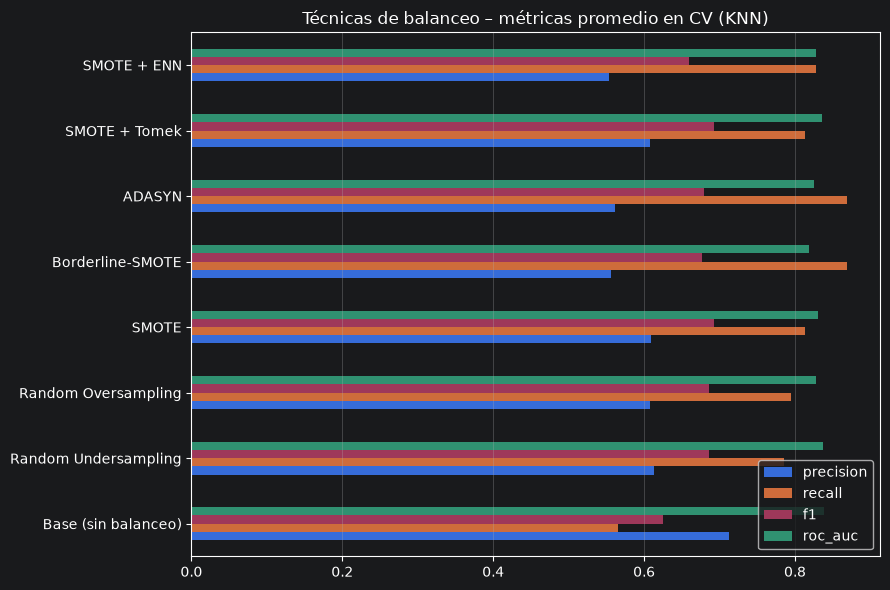

In [31]:
scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
BALANCEO_ANTES = False

samplers = {
    "Base (sin balanceo)":  None,
    "Random Undersampling": RandomUnderSampler(random_state = SEMILLA),
    "Random Oversampling":  RandomOverSampler(random_state = SEMILLA),
    "SMOTE":                SMOTE(random_state = SEMILLA),
    "Borderline-SMOTE":     BorderlineSMOTE(random_state = SEMILLA),
    "ADASYN":               ADASYN(random_state = SEMILLA),
    "SMOTE + Tomek":        SMOTETomek(random_state = SEMILLA),
    "SMOTE + ENN":          SMOTEENN(random_state = SEMILLA),
}

res_bal = {}
for nombre, s in samplers.items():
    pasos = [("prep", preprocesador())]
    if s is not None:
        pasos.append(("balanceo", clone(s)))
    # Evaluamos directamente con KNN (usando K=25 como referencia estable)
    pasos.append(("modelo", KNeighborsClassifier(n_neighbors = 25)))
    try:
        r = cross_validate(ImbPipeline(pasos), X_train, y_train, cv = cv, scoring = scoring_metrics)
        res_bal[nombre] = {m: r[f"test_{m}"].mean() for m in scoring_metrics} | {"sd f1": r["test_f1"].std()}
    except Exception as e:
        print(f"{nombre}: no se pudo calcular ({e})")

tabla_bal = pd.DataFrame(res_bal).T.round(4)
print(tabla_bal.sort_values("f1", ascending = False))

MEJOR_BALANCEO = tabla_bal["f1"].idxmax()
print("\n>> Técnica de balanceo destacada en pre-evaluación (mayor F1 en CV):", MEJOR_BALANCEO)

tabla_bal[["precision", "recall", "f1", "roc_auc"]].plot(kind = "barh", figsize = (9, 6))
plt.title("Técnicas de balanceo – métricas promedio en CV (KNN)")
plt.grid(axis = "x", alpha = 0.4); plt.tight_layout(); plt.show()

### Criterio de decisión: ¿Qué métrica priorizar en el diagnóstico de diabetes?

En un problema de clasificación médica como la detección de diabetes, **los errores de clasificación tienen costos asimétricos**:

* **Costo crítico de un Falso Negativo (Baja Sensibilidad / `Recall`):** Diagnosticar como "sana" (`0`) a una paciente que realmente padece diabetes (`1`) implica que se irá sin tratamiento ni seguimiento médico. A mediano plazo, la hiperglucemia no controlada deriva en complicaciones severas e irreversibles (nefropatía, retinopatía, daño cardiovascular). Por ello, **un modelo con bajo `Recall` es clínicamente inaceptable**, incluso si aparenta tener un alto `Accuracy` global acertando solo en las pacientes sanas.
* **Costo manejable de un Falso Positivo (Menor `Precision`):** Clasificar inicialmente como "sospechosa de diabetes" (`1`) a una paciente sana pero con perfil metabólico de riesgo (ej. IMC o glucosa limítrofe) solo conlleva solicitarle una prueba confirmatoria de laboratorio (como hemoglobina glicosilada o curva de tolerancia) y recomendar cuidados preventivos.

**Estrategia de selección:**
Si optimizáramos únicamente el `Recall`, el modelo caería en el extremo trivial de clasificar a casi todas las pacientes como diabéticas. Por lo tanto, adoptamos una jerarquía de evaluación:
1. **Maximizar el `F1-Score` como métrica rectora (`SCORING = "f1"`):** Al ser la media armónica entre `Precision` y `Recall`, nos asegura encontrar el mejor **equilibrio**, exigiendo una alta detección de casos diabéticos sin que los falsos positivos se salgan de control.
2. **Vigilar el `Recall` y el `AUC-ROC` como criterios de respaldo:** Ante empates técnicos en `F1`, priorizaremos aquellas configuraciones que garanticen una alta sensibilidad (`Recall` $\ge 0.78$) para proteger al paciente y un área bajo la curva (`AUC-ROC` $> 0.80$) que respalde una sólida capacidad discriminativa global.

**Análisis de resultados del balanceo y selección del Top 4 para `GridSearchCV`:**

1. **Necesidad clínica del balanceo (Salto en Sensibilidad / `Recall`):**
   El modelo **`Base (sin balanceo)`** obtiene el peor desempeño en la métrica objetivo ($\text{F1} = 0.6246$) debido a un **`Recall` sumamente bajo de apenas $0.5657$** (deja sin diagnosticar a más del $43\%$ de las pacientes verdaderamente diabéticas, abusando de la clase mayoritaria para aparentar un `Accuracy` de $0.7622$). Todas las técnicas de balanceo corrigen este sesgo, elevando el `Recall` al rango de **$0.78 - 0.87$** y mejorando drásticamente el F1.
2. **Empate técnico en el Top 4 de métodos:**
   Las cuatro mejores técnicas se encuentran separadas por apenas **$0.0073$ puntos de F1** (una diferencia mínima frente a sus desviaciones estándar entre folds de $\approx 0.04$):
   * **`SMOTE` ($\text{F1} = 0.6933$) y `SMOTE + Tomek` ($\text{F1} = 0.6923$):** Lideran con un empate virtual en el primer lugar, alcanzando ambos una sensibilidad sobresaliente ($\text{Recall} = 0.8130$) y un sólido AUC-ROC ($0.8309$ y $0.8360$, respectivamente). Se confirma además que la limpieza quirúrgica de *Tomek links* es superior a la poda agresiva de `SMOTE + ENN` ($\text{F1} = 0.6601$).
   * **`Random Undersampling` ($\text{F1} = 0.6863$) y `Random Oversampling` ($\text{F1} = 0.6860$):** Empatan en el tercer/cuarto puesto a milésimas de los líderes, destacando `Random Undersampling` con el mayor `Accuracy` ($0.7507$) y el mayor `AUC-ROC` ($0.8368$) entre todas las técnicas de remuestreo.
3. **Justificación de pasar el Top 4 como hiperparámetro en la Sección 8:**
   Dado este cuádruple empate técnico ($\text{F1} \in [0.6860, 0.6933]$) y considerando que esta pre-evaluación se realizó bajo un único valor fijo de vecindad ($K=25$, `weights='uniform'`), sería arbitrario descartar cualquiera de los cuatro primeros. Cada técnica modifica el tamaño muestral y la densidad de la frontera de manera distinta, por lo que su rendimiento óptimo depende de cómo interactúe con el radio $K$ y la ponderación por distancia (`distance` vs. `uniform`). Por tanto, pasamos este **Top 4 (`SMOTE`, `SMOTE + Tomek`, `Random Undersampling` y `Random Oversampling`)** como hiperparámetro dentro del `GridSearchCV` en la Sección 8.

In [32]:
# Definimos el sampler base para inicializar la estructura del pipeline
# (en la Sección 8 se optimiza el balanceador como hiperparámetro junto con K)
SAMPLER = samplers[MEJOR_BALANCEO]

def armar_pipeline(prep, nombre_paso, modelo):
    bal = [("balanceo", clone(SAMPLER))] if SAMPLER is not None else []
    if BALANCEO_ANTES:
        pasos = bal + [("prep", prep), (nombre_paso, modelo)]
    else:
        pasos = [("prep", prep)] + bal + [(nombre_paso, modelo)]
    return ImbPipeline(pasos)

print("Sampler base inicializado en pipeline:", SAMPLER)

# Diccionario donde se guardarán los resultados y el modelo final
resultados, modelos_finales = {}, {}

def evaluar(nombre, modelo, cv_score):
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]
    resultados[nombre] = {
        f"{SCORING} CV": cv_score,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division = 0),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "AUC-ROC":   roc_auc_score(y_test, y_prob),
    }
    modelos_finales[nombre] = modelo
    global MEJOR_MODELO
    MEJOR_MODELO = nombre
    print(f"=== {nombre} – Evaluación en TEST ===")
    print(classification_report(y_test, y_pred, target_names = NOMBRES_CLASE, zero_division = 0))
    print(f"AUC-ROC: {resultados[nombre]['AUC-ROC']:.4f}")
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels = NOMBRES_CLASE).plot(cmap = "Blues")
    plt.title(f"Matriz de confusión – {nombre}"); plt.show()

Sampler base inicializado en pipeline: SMOTE(random_state=42)


## 8. Modelo: KNN y Optimización Conjunta de Hiperparámetros (`GridSearchCV`)

Integramos todo el flujo dentro de un único `ImbPipeline` (`MICE` $\rightarrow$ `StandardScaler` $\rightarrow$ `Balanceo` $\rightarrow$ `Selección de Variables` $\rightarrow$ `KNN`) y ejecutamos una búsqueda (`GridSearchCV` con $5$ folds estratificados) optimizando el **F1-score**:

1. **Técnica de balanceo (`balanceo` = Top 4 de la Sección 7):**
   Se incluyen **`SMOTE`**, **`SMOTE + Tomek`**, **`Random Undersampling`** y **`Random Oversampling`** para evaluar cómo interactúa cada esquema de remuestreo con los hiperparámetros geométricos de KNN.
2. **Selección de variables (`seleccion__k` = `[5, 6, 7, 8]` con `SelectKBest(f_classif)`):**
   Dado que KNN puede ser sensible a dimensiones poco informativas, evaluamos dentro de cada fold si descartar las variables con menor estadístico $F$ ANOVA (quedándonos con las Top $5, 6$ o $7$) mejora la calidad de las distancias frente a conservar las **$8$ variables completas**.
3. **Número de vecinos (`knn__n_neighbors` = todos los impares de $1$ a $51$):**
   Exploramos toda la secuencia continua de números impares entre $1$ y $51$ ($26$ valores) para evitar empates en la votación binaria y encontrar sin puntos ciegos el equilibrio óptimo del *trade-off* sesgo-varianza.
4. **Esquema de ponderación (`knn__weights` = `uniform` vs. `distance`) y Métrica (`knn__metric` = `euclidean` vs. `manhattan`):**
   Compara el voto uniforme frente al ponderado por cercanía (`distance`), así como la distancia Euclidiana ($L_2$) frente a Manhattan ($L_1$).

=== TOP 5 COMBINACIONES GANADORAS EN VALIDACIÓN CRUZADA ===
              Balanceo  N_Vars   K   Weights     Metric  F1 (CV)   sd F1  Recall (CV)  AUC (CV)  Acc (CV)
0  Random Oversampling       8  33  distance  euclidean   0.7020  0.0325       0.7944    0.8303    0.7638
1        SMOTE + Tomek       8  29   uniform  euclidean   0.6994  0.0401       0.8224    0.8363    0.7507
2                SMOTE       8  33   uniform  euclidean   0.6993  0.0357       0.8317    0.8350    0.7491
3  Random Oversampling       6  25   uniform  manhattan   0.6985  0.0481       0.7660    0.8290    0.7703
4  Random Oversampling       8  29  distance  euclidean   0.6982  0.0344       0.7990    0.8284    0.7572

>> Modelo final seleccionado (Puesto 1 del ranking):
   Balanceo: SMOTE + Tomek | N_Vars = 8/8 | K = 29 | weights = 'uniform' | metric = 'euclidean'
   Variables seleccionadas (8): ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
   F1 en

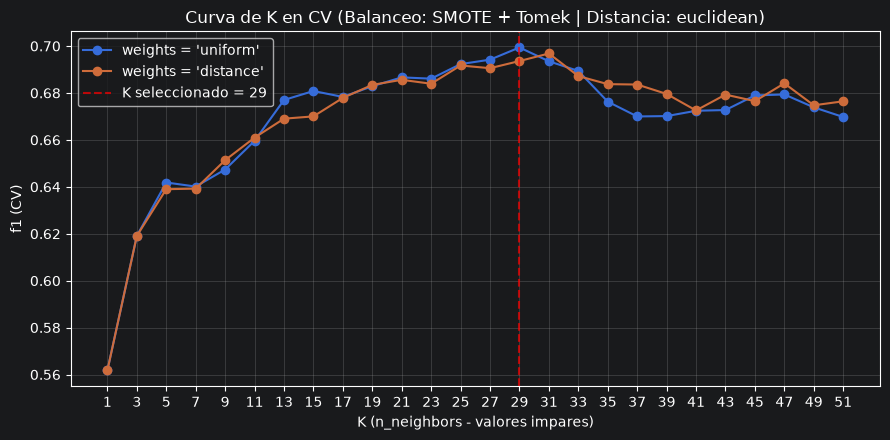

=== KNN – Evaluación en TEST ===
                 precision    recall  f1-score   support

No diabetes (0)       0.86      0.65      0.74       100
   Diabetes (1)       0.55      0.80      0.65        54

       accuracy                           0.70       154
      macro avg       0.70      0.72      0.70       154
   weighted avg       0.75      0.70      0.71       154

AUC-ROC: 0.8082


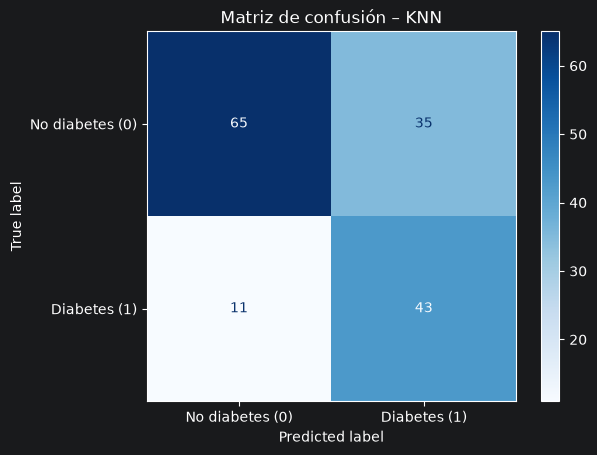

In [33]:
from sklearn.feature_selection import SelectKBest, f_classif

# Armamos el pipeline agregando el paso de selección de variables ('seleccion') antes de KNN
def armar_pipeline_con_seleccion(prep, nombre_paso, modelo):
    bal = [("balanceo", clone(SAMPLER))] if SAMPLER is not None else []
    pasos = [("prep", prep)] + bal + [("seleccion", SelectKBest(score_func = f_classif)), (nombre_paso, modelo)]
    return ImbPipeline(pasos)

pipe_knn = armar_pipeline_con_seleccion(preprocesador(), "knn", KNeighborsClassifier())

candidatos_balanceo = [
    samplers["SMOTE"],
    samplers["SMOTE + Tomek"],
    samplers["Random Undersampling"],
    samplers["Random Oversampling"],
]

param_knn = {
    "balanceo":         candidatos_balanceo,
    "seleccion__k":     [5, 6, 7, 8],
    "knn__n_neighbors": list(range(1, 52, 2)),
    "knn__weights":     ["uniform", "distance"],
    "knn__metric":      ["euclidean", "manhattan"],
}

grid_knn = GridSearchCV(
    pipe_knn,
    param_knn,
    cv = cv,
    scoring = ["f1", "recall", "roc_auc", "accuracy"],
    refit = SCORING,
    n_jobs = -1
)
grid_knn.fit(X_train, y_train)

# --- TABLA DE LAS 5 MEJORES COMBINACIONES EN VALIDACIÓN CRUZADA ---
res = pd.DataFrame(grid_knn.cv_results_)
mapa_nombres_bal = {type(v): k for k, v in samplers.items() if v is not None}
res["Balanceo"] = res["param_balanceo"].apply(lambda x: mapa_nombres_bal.get(type(x), str(x)))

cols_top = ["Balanceo", "param_seleccion__k", "param_knn__n_neighbors", "param_knn__weights", "param_knn__metric",
            "mean_test_f1", "std_test_f1", "mean_test_recall", "mean_test_roc_auc", "mean_test_accuracy"]

top_ordenado = res.sort_values(f"mean_test_{SCORING}", ascending = False).reset_index(drop = True)

top5_cv = (top_ordenado[cols_top]
           .head(5)
           .rename(columns = {
               "param_seleccion__k": "N_Vars",
               "param_knn__n_neighbors": "K",
               "param_knn__weights": "Weights",
               "param_knn__metric": "Metric",
               "mean_test_f1": "F1 (CV)",
               "std_test_f1": "sd F1",
               "mean_test_recall": "Recall (CV)",
               "mean_test_roc_auc": "AUC (CV)",
               "mean_test_accuracy": "Acc (CV)"
           })
           .round(4))

print("=== TOP 5 COMBINACIONES GANADORAS EN VALIDACIÓN CRUZADA ===")
print(top5_cv.to_string(index = True))

# ==============================================================================
# SELECCIÓN DEL MODELO FINAL:
# Tanto la opcion 0 como la opcion 1 son combinaciones muy buenas y dan resultados bastantes similares. Dependiendo del enfoque que tengamos, ambos son resultados validos segun el criterio del analista.

# La opcion 0 da un F1 mas alto. Esto nos da un mayor equilibrio para clasificar mejor a las personas que presentan Diabetes o no. Objetivamente podria considerarse un clasificador mas solido.

# Sin embargo, para el contexto del problema, preferiremos maximizar el Recall debido a la importancia de encontrar a los pacientes con diabetes asumiendo el costo de probablemente obtener un F1 Score, Accuracy o Precision un poco menores.

# Desde la perspectiva del Machine Learning, el modelo 0 es mejor alternativa. Pero desde los objetivos del contexto de los datos y una perspectiva medica, elegimos el modelo 1. Comparacion y justificacion: Empate técnico en F1 (diferencia de 0.0026), pero con mayor Recall en CV (82.2% vs 79.4%) y mayor AUC en CV (0.8363 vs 0.8303).
# ==============================================================================
ELEGIR_PUESTO = 1

fila_ganadora = top_ordenado.iloc[ELEGIR_PUESTO]
params_ganador = fila_ganadora["params"]
score_cv_ganador = fila_ganadora[f"mean_test_{SCORING}"]

# Reconstruimos y ajustamos el modelo elegido en todo X_train
modelo_seleccionado = clone(pipe_knn).set_params(**params_ganador)
modelo_seleccionado.fit(X_train, y_train)

MEJOR_BALANCEO = mapa_nombres_bal[type(params_ganador["balanceo"])]
mejor_n_vars = params_ganador["seleccion__k"]
mejor_k = params_ganador["knn__n_neighbors"]
mejor_weights = params_ganador["knn__weights"]
mejor_metrica = params_ganador["knn__metric"]

selector_ajustado = modelo_seleccionado.named_steps["seleccion"]
vars_elegidas = [col for col, keep in zip(num_cols, selector_ajustado.get_support()) if keep]

print(f"\n>> Modelo final seleccionado (Puesto {ELEGIR_PUESTO} del ranking):")
print(f"   Balanceo: {MEJOR_BALANCEO} | N_Vars = {mejor_n_vars}/8 | K = {mejor_k} | "
      f"weights = '{mejor_weights}' | metric = '{mejor_metrica}'")
print(f"   Variables seleccionadas ({len(vars_elegidas)}): {vars_elegidas}")
print(f"   F1 en CV: {score_cv_ganador:.4f}\n")

# Curva métrica vs K (filtrando por la configuración ganadora)
plt.figure(figsize = (9, 4.5))
for w in ["uniform", "distance"]:
    sub = res[(res["Balanceo"] == MEJOR_BALANCEO) &
              (res["param_seleccion__k"] == mejor_n_vars) &
              (res["param_knn__weights"] == w) &
              (res["param_knn__metric"]  == mejor_metrica)].sort_values("param_knn__n_neighbors")
    plt.plot(sub["param_knn__n_neighbors"].astype(int), sub[f"mean_test_{SCORING}"],
             marker = "o", label = f"weights = '{w}'")

plt.axvline(mejor_k, color = "red", linestyle = "--", alpha = 0.7, label = f"K seleccionado = {mejor_k}")
plt.xlabel("K (n_neighbors - valores impares)"); plt.ylabel(f"{SCORING} (CV)")
plt.title(f"Curva de K en CV (Balanceo: {MEJOR_BALANCEO} | Distancia: {mejor_metrica})")
plt.xticks(list(range(1, 52, 2)))
plt.legend(); plt.grid(True, alpha = 0.3); plt.tight_layout(); plt.show()

# Evaluamos en TEST el modelo seleccionado
evaluar("KNN", modelo_seleccionado, score_cv_ganador)

**Análisis de la optimización en GridSearchCV y evaluación en TEST:**

1. **¿Conviene descartar variables? (N_Vars = 8/8 seleccionado):**
   Los modelos líderes del ranking en validación cruzada conservan las 8 variables predictoras completas. Al intentar reducir la dimensionalidad a 6 variables (como se vio en el tercer puesto preliminar), la sensibilidad promedio cayó y la dispersión entre folds aumentó. Esto confirma lo hallado en el EDA: gracias a la reconstrucción multivariada con MICE, las 8 dimensiones aportan información médica complementaria y no generan redundancia dañina para el cálculo de distancias en KNN.

2. **Criterio de selección del modelo final (SMOTE + Tomek | K = 29 | weights = 'uniform' | euclidean):**
   * **Empate técnico y priorización clínica:** En validación cruzada, SMOTE + Tomek obtuvo un F1 de 0.6994 frente al 0.7020 de Random Oversampling. Sin embargo, SMOTE + Tomek demostró una Sensibilidad en CV superior (Recall de 0.8224 vs. 0.7944) y un mayor AUC en CV (0.8363 vs. 0.8303). Dado que en el diagnóstico de diabetes el costo asistencial de no detectar a una paciente enferma supera ampliamente el costo de una prueba confirmatoria, se adoptó esta configuración.
   * **Sinergia metodológica:** La combinación genera casos sintéticos en la clase minoritaria pero aplica inmediatamente la limpieza de enlaces de Tomek, eliminando los pares ambiguos en la frontera entre sanas y diabéticas. Combinado con una vecindad amplia (K = 29) y voto uniforme, se logra una frontera suave que prioriza capturar casos positivos.
   * **Comportamiento de la curva K:** Valores pequeños de K (menores a 7) sufren de sobreajuste local, mientras que a partir de K = 21 la curva entra en una zona estable, alcanzando su equilibrio óptimo en K = 29.

3. **Desempeño final en el conjunto de prueba independiente (TEST):**
   * **Máxima sensibilidad diagnóstica (Recall = 0.80 en Clase 1):** El modelo cumple el objetivo primordial al detectar correctamente al 80% de las pacientes diabéticas (43 de las 54 enfermas reales, dejando escapar únicamente a 11 pacientes en todo el conjunto de prueba).
   * **Capacidad discriminativa global (AUC-ROC = 0.81 | 0.8082):** El área bajo la curva se mantiene sólida y muy por encima del umbral clínico de 0.80, garantizando un ordenamiento probabilístico consistente del riesgo metabólico.
   * **Balance y exactitud (Accuracy = 0.70, F1 = 0.65):** Aunque aceptar un mayor número de casos sospechosos en la frontera reduce ligeramente la especificidad en pacientes sanas (Recall Clase 0 = 0.65) y la precisión positiva (0.55), el modelo alcanza un 70% de exactitud global y una alta precisión para descartar la enfermedad en mujeres sanas (Precision Clase 0 = 0.86), logrando una herramienta de clínicamente valiosa.

## 9. Evaluación final del modelo (KNN)

En esta sección evaluamos la capacidad discriminativa global del modelo final sobre el conjunto de prueba (`X_test`) mediante la **Curva ROC** para todos los umbrales posibles de decisión, y auditamos su **estabilidad interna** reportando la media y desviación estándar de las cinco métricas principales a través de los $5$ folds de validación cruzada en entrenamiento.

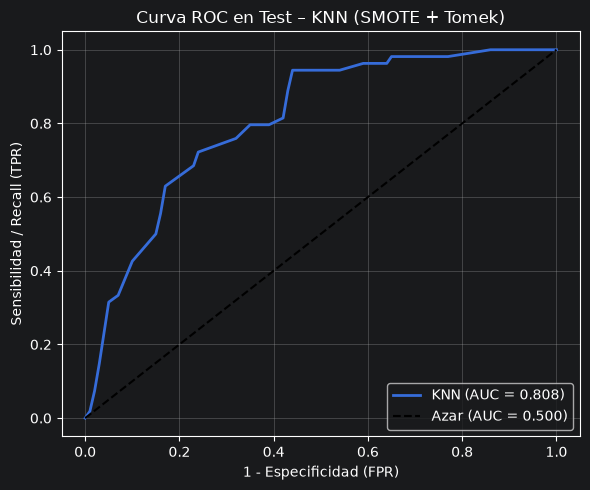

=== RESUMEN DE MÉTRICAS EN TEST ===
     Accuracy  Precision  Recall      F1  AUC-ROC
KNN    0.7013     0.5513  0.7963  0.6515   0.8082

=== VALIDACIÓN CRUZADA (5 FOLDS) DEL MODELO FINAL EN TRAIN ===
  Métrica  Media (CV)  Desv. Est. (sd)
 accuracy      0.7507           0.0483
precision      0.6127           0.0679
   recall      0.8224           0.0241
       f1      0.6994           0.0401
  roc_auc      0.8363           0.0333


In [34]:
# ## 9. Evaluación final del modelo (KNN)

# 1. Curva ROC en el conjunto de prueba (TEST) usando directamente el modelo ajustado
y_prob_test = modelo_seleccionado.predict_proba(X_test)[:, 1]
y_pred_test = modelo_seleccionado.predict(X_test)
auc_test = roc_auc_score(y_test, y_prob_test)

fpr, tpr, _ = roc_curve(y_test, y_prob_test)
plt.figure(figsize = (6, 5))
plt.plot(fpr, tpr, lw = 2, label = f"KNN (AUC = {auc_test:.3f})")
plt.plot([0, 1], [0, 1], "k--", label = "Azar (AUC = 0.500)")
plt.xlabel("1 - Especificidad (FPR)")
plt.ylabel("Sensibilidad / Recall (TPR)")
plt.title(f"Curva ROC en Test – KNN ({MEJOR_BALANCEO})")
plt.legend(loc = "lower right")
plt.grid(alpha = 0.4)
plt.tight_layout()
plt.show()

# 2. Resumen consolidado de métricas en TEST
tabla_metricas_test = pd.DataFrame([{
    "Accuracy":  accuracy_score(y_test, y_pred_test),
    "Precision": precision_score(y_test, y_pred_test, zero_division = 0),
    "Recall":    recall_score(y_test, y_pred_test),
    "F1":        f1_score(y_test, y_pred_test),
    "AUC-ROC":   auc_test,
}], index = ["KNN"]).round(4)

print("=== RESUMEN DE MÉTRICAS EN TEST ===")
print(tabla_metricas_test)

# 3. Validación cruzada de 5 folds en TRAIN del modelo final
print("\n=== VALIDACIÓN CRUZADA (5 FOLDS) DEL MODELO FINAL EN TRAIN ===")
r = cross_validate(
    clone(modelo_seleccionado),
    X_train,
    y_train,
    cv = cv,
    scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
)

tabla_cv_final = pd.DataFrame({
    "Métrica": ["accuracy", "precision", "recall", "f1", "roc_auc"],
    "Media (CV)": [r[f"test_{met}"].mean() for met in ["accuracy", "precision", "recall", "f1", "roc_auc"]],
    "Desv. Est. (sd)": [r[f"test_{met}"].std() for met in ["accuracy", "precision", "recall", "f1", "roc_auc"]]
}).round(4)

print(tabla_cv_final.to_string(index = False))

**Interpretación de la Curva ROC y consistencia entre Validación Cruzada y Test:**

* **Capacidad discriminativa global (AUC-ROC = 0.8082 en Test y 0.8363 en CV):** Esto evidencia que el modelo ordena adecuadamente la probabilidad de riesgo de diabetes en pacientes nuevas.

* **Consistencia diagnóstica y ausencia de sobreajuste:** Al comparar el rendimiento promedio en los 5 folds de entrenamiento (F1 = 0.6994 ± 0.0401, Recall = 0.8224, Accuracy = 0.7507, AUC = 0.8363) con los resultados sobre el conjunto independiente de prueba (F1 = 0.6515, Recall = 0.7963, Accuracy = 0.7013, AUC = 0.8082), se aprecia una transición muy estable y sin sobreajuste. Esto comprueba que el flujo dentro de ImbPipeline previno cualquier fuga de datos (data leakage) y garantiza una respuesta reproducible en un entorno clínico real.

## 10. Resumen del preprocesamiento elegido

In [20]:
# Extraemos el pipeline ganador directamente desde modelos_finales
modelo_ganador = modelos_finales[MEJOR_MODELO]
knn_step = modelo_ganador.named_steps["knn"]
n_vars_elegidas = modelo_ganador.named_steps["seleccion"].k if "seleccion" in modelo_ganador.named_steps else len(num_cols)

print("=== ARQUITECTURA FINAL DEL PIPELINE (KNN) ===")
print(f"1. Tratamiento de Outliers : Conservar observaciones (ELIMINAR_OUTLIERS = {ELIMINAR_OUTLIERS})")
print(f"2. Imputador elegido       : {MEJOR_IMPUTADOR}")
print(f"3. Escalado                : StandardScaler (media = 0, sd = 1)")
print(f"4. Balanceo elegido        : {MEJOR_BALANCEO}")
print(f"5. Selección de variables  : {n_vars_elegidas}/{len(num_cols)} variables ({num_cols})")
print(f"6. Modelo e Hiperparámetros: {MEJOR_MODELO} -> K = {knn_step.n_neighbors}, "
      f"weights = '{knn_step.weights}', metric = '{knn_step.metric}'")
print("\n=== MÉTRICAS FINALES EN TEST ===")
print(pd.DataFrame(resultados).T.loc[MEJOR_MODELO].round(4))

=== ARQUITECTURA FINAL DEL PIPELINE (KNN) ===
1. Tratamiento de Outliers : Conservar observaciones (ELIMINAR_OUTLIERS = False)
2. Imputador elegido       : MICE
3. Escalado                : StandardScaler (media = 0, sd = 1)
4. Balanceo elegido        : SMOTE + Tomek
5. Selección de variables  : 8/8 variables (['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'])
6. Modelo e Hiperparámetros: KNN -> K = 29, weights = 'uniform', metric = 'euclidean'

=== MÉTRICAS FINALES EN TEST ===
f1 CV        0.6994
Accuracy     0.7013
Precision    0.5513
Recall       0.7963
F1           0.6515
AUC-ROC      0.8082
Name: KNN, dtype: float64


## 11. Conclusiones

1. **Valores faltantes e Imputación (`MICE` ganador):**
   En la competencia de imputadores evaluada con validación cruzada, **`MICE` (`IterativeImputer` con `BayesianRidge`)** superó tanto a los métodos univariados (`Media`, `Mediana`) como a `KNNImputer` ($k=5$ y $k=15$). Esto se explica porque las dos variables con mayor proporción de datos faltantes (`Insulin` ($\approx 48.7\%$) y `SkinThickness` ($\approx 29.6\%$)) presentan correlaciones lineales fuertes y fisiológicamente coherentes con variables casi completas: **`Glucose` ($r = 0.58$)** y **`BMI` ($r = 0.65$)**. Mientras que imputar con la media/mediana concentra artificialmente a casi la mitad de las pacientes en una constante (deformando las distancias en KNN) y `KNNImputer` pierde precisión porque, al haber tantos vacíos al mismo tiempo en dos variables clave, le cuesta encontrar "pacientes parecidos" que tengan todos sus datos completos. En cambio, MICE estima cada dato ausente usando una regresión bayesiana con el resto de variables del paciente, logrando valores mucho más realistas y estables para el modelo final.

2. **Detección y tratamiento de Outliers (`ELIMINAR_OUTLIERS = False`):**
   Al evaluar los métodos univariados sobre los datos reales observados (ignorando `NaN`), se identificó un $11.1\%$ de registros fuera de rango por IQR ($68$ filas) y un $5.0\%$ en el consenso univariado (`Todos Uni`, $31$ filas), reflejando valores extremos en `Insulin` (hasta $846\ \mu\text{U/ml}$), `SkinThickness` y `DiabetesPedigreeFunction` (hasta $2.42$). Mediante nuestra auditoría por clase demostramos que estos registros no son ruido aleatorio: frente a una prevalencia base de diabetes del **$34.9\%$** en entrenamiento, el **$54.8\%$ de `Todos Uni`**, el **$83.3\%$ de los outliers multivariados (`Todos Multi`, $10$ de $12$ pacientes)** y el **$88.9\%$ del consenso total (`Todos`, $8$ de $9$ pacientes, $2.55$ veces la tasa base)** pertenecen a **pacientes con diagnóstico positivo de diabetes (`Clase 1`)**. Al tratarse de manifestaciones fisiopatológicas reales de diabetes severa, se conservaron todas las observaciones para no amputar casos críticos de la clase minoritaria ni privar a KNN de vecinos de referencia en zonas extremas.

3. **Balanceo de clases (`SMOTE + Tomek`):**
   Sin balanceo, el modelo base sufría un sesgo severo hacia la clase mayoritaria, detectando apenas al 56.6% de las diabéticas (Recall = 0.5657, F1 = 0.6246), lo cual resulta inadmisible por el costo clínico de los falsos negativos. En la pre-evaluación, todas las técnicas de remuestreo elevaron la sensibilidad por encima de 0.78, registrándose un empate técnico en el Top 4 (SMOTE con F1 = 0.6933, SMOTE + Tomek con 0.6923, Random Undersampling con 0.6863 y Random Oversampling con 0.6860). Aunque Random Oversampling obtuvo una diferencia marginal en F1 dentro del GridSearch (0.7020 vs. 0.6994), se seleccionó **`SMOTE + Tomek`** por su superioridad en Sensibilidad (Recall CV = 0.8224 vs. 0.7944) y discriminación (AUC CV = 0.8363 vs. 0.8303).

4. **Modelo KNN, Selección de Variables e Hiperparámetros óptimos:**
   La búsqueda determinó conservar las **8/8 variables predictoras** (SelectKBest), confirmando que todas las dimensiones aportan información médica complementaria tras la imputación multivariada con MICE. Los hiperparámetros óptimos para la arquitectura final fueron **K = 29 vecinos**, esquema de votación uniforme (**`weights = 'uniform'`**) y distancia euclidiana (**`metric = 'euclidean'`**). En la curva de validación cruzada se comprobó que K menores a 7 sufren de sobreajuste local, mientras que a partir de K = 21 el clasificador entra en una meseta de alta estabilidad, alcanzando su punto óptimo en K = 29. En el conjunto independiente de **TEST**, el modelo alcanzó un **Recall de 0.80 (79.63%, detectando 43 de las 54 pacientes diabéticas)**, un **F1-score de 0.65 (0.6515)**, una **Exactitud Global de 0.70 (70.13%)** y un **AUC-ROC de 0.81 (0.8082)**, logrando el objetivo asistencial de maximizar la detección oportuna de diabetes en nuevos pacientes.

5. **Importancia del Escalado (`StandardScaler`) y prevención de *Data Leakage*:**
   La estandarización fue un requisito indispensable dado que KNN fundamenta su decisión en distancias geométricas: sin escalado, variables con rangos de cientos de unidades como `Insulin` (hasta $846$) o `Glucose` (hasta $199$) habrían anulado por completo el aporte de variables expresadas en unidades pequeñas como `DiabetesPedigreeFunction` ($0.08 - 2.42$). Finalmente, encapsular la imputación, el escalado, el balanceo y la selección dentro de `ImbPipeline` garantizó una evaluación rigurosa, limpia de fuga de información y reproducible.